# 3. Entrenamiento fold a fold y evaluación

Con la arquitectura seleccionada para cada (lag, H) entrenamos el MLP multisalida fold a fold con las tres estrategias de `timeseries-cv` (Group K-Fold, Forward Chaining y K-Fold) y calculamos, en USD y sobre validación, MAPE, MAE, RMSE y MSE por paso de horizonte y agregados, junto con el p-valor BDS de los residuos de h = 1. Comparamos con dos referencias: `MLPRegressor` de scikit-learn y el pronóstico ingenuo (último precio observado repetido H días). El modelo final de cada configuración, reentrenado con toda la serie previa al hold-out, se evalúa aparte en el hold-out.

Este notebook no entrena: lee los resultados de las fases F5 y F6 de `src/train_t2.py`.

In [1]:
# Rutas: en Colab se usa la carpeta de Drive; en el repositorio, la raíz del proyecto.
import os, glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DRIVE = Path("/content/drive/MyDrive/tarea2_series")
if DRIVE.exists():
    BASE, FIGS = DRIVE, DRIVE / "figs"
else:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FIGS = BASE / "notebooks" / "figs"
RESULTS = BASE / os.environ.get("T2_RESULTS_DIR", "results")
FIGS.mkdir(parents=True, exist_ok=True)

LAGS, HS, ESTRATEGIAS = [7, 14, 21, 28], [7, 14, 21, 28], ["gk", "fc", "kf"]
NOMBRE = {"gk": "Group K-Fold", "fc": "Forward Chaining", "kf": "K-Fold"}
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # orden categorico fijo
COL_EST = dict(zip(ESTRATEGIAS, COL))
COL_LAG = dict(zip(LAGS, COL))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.prop_cycle": plt.cycler(color=COL), "lines.linewidth": 1.6,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.labelsize": 10})

df = pd.read_csv(BASE / "data" / "btc_1d.csv", parse_dates=["date"])
y = df["close"].to_numpy(float)
DATES = df["date"].to_numpy()
N_HOLD = max(int(len(y) * 0.10), 56)
N_CV = len(y) - N_HOLD


def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight", dpi=150)

In [2]:
def cargar_registros():
    R = {}
    for f in sorted(glob.glob(str(RESULTS / "raw" / "*.jsonl"))):
        for line in open(f):
            if line.strip():
                r = json.loads(line); R[r["id"]] = r
    return list(R.values())

REG = cargar_registros()
print(f"{len(REG)} registros en {RESULTS / 'raw'}")
print(pd.Series([r["phase"] for r in REG]).value_counts().to_string())

7435 registros en /content/drive/MyDrive/tarea2_series/results/raw
search       7211
top5           80
eval_rep       48
detail         48
eval_own       32
final_rep      16


In [3]:
DET = {(r["L"], r["H"], r["strat"]): r for r in REG if r["phase"] == "detail"}
FIN = {(r["L"], r["H"]): r for r in REG if r["phase"] == "top5" and r.get("saved")}
print(f"Detalle por fold: {len(DET)} de 48 | modelos finales: {len(FIN)} de 16")

def fila(m, bds=None):
    return dict(MAPE=m["mape"], MAE=m["mae"], RMSE=m["rmse"], MSE=m["mse"], BDS_pvalue_h1=bds)

def tabla_folds(L, H, s):
    d = DET[(L, H, s)]
    t = pd.DataFrame([dict(Fold=f"Fold {f['fold']+1}", n_val=f["n_val"], **fila(f["keras_val"], f["bds_p_h1"]))
                      for f in d["folds"]]).set_index("Fold")
    num = t.drop(columns="n_val").astype(float)
    t.loc["Mean"] = num.mean(); t.loc["Std"] = num.std()
    return t

Detalle por fold: 48 de 48 | modelos finales: 16 de 16


## 3.1 Métricas por fold (validación, USD)

Mostramos la configuración representativa (lag 14, H 14) con las tres estrategias. Las tablas de las 48 combinaciones quedan en `results/metricas_val_por_fold.csv`.

In [4]:
largas = []
for (L, H, s), d in DET.items():
    for f in d["folds"]:
        largas.append(dict(estrategia=NOMBRE[s], lag=L, H=H, fold=f["fold"] + 1, n_train=f["n_train"],
                           n_val=f["n_val"], **fila(f["keras_val"], f["bds_p_h1"]),
                           RMSE_mlpregressor=f["mlpreg_val"]["rmse"], RMSE_ingenuo=f["naive_val"]["rmse"]))
LARGA = pd.DataFrame(largas).sort_values(["estrategia", "lag", "H", "fold"])
LARGA.to_csv(RESULTS / "metricas_val_por_fold.csv", index=False)
for s in ESTRATEGIAS:
    if (14, 14, s) in DET:
        print(f"\n{NOMBRE[s]} — lag 14, H 14")
        display(tabla_folds(14, 14, s).round(3))


Group K-Fold — lag 14, H 14


,n_val,MAPE,MAE,RMSE,MSE,BDS_pvalue_h1
Fold,,,,,,
Fold 1,84.0,14.058,2617.873,3589.839,1.288695e+07,0.0
Fold 2,84.0,8.064,2099.460,3232.959,1.045203e+07,0.0
Fold 3,84.0,8.679,2140.165,3228.673,1.042433e+07,0.0
Fold 4,84.0,8.792,2652.541,4651.123,2.163294e+07,0.0
Fold 5,84.0,9.563,2479.151,3919.536,1.536277e+07,0.0
Mean,NaN,9.831,2397.838,3724.426,1.415180e+07,0.0
Std,NaN,2.422,262.357,592.085,4.653390e+06,0.0



Forward Chaining — lag 14, H 14


,n_val,MAPE,MAE,RMSE,MSE,BDS_pvalue_h1
Fold,,,,,,
Fold 1,1.0,3.902,1889.573,2142.049,4.588374e+06,None
Fold 2,1.0,7.808,1595.651,1804.684,3.256885e+06,None
Fold 3,1.0,4.517,1231.405,1357.546,1.842931e+06,None
Fold 4,1.0,9.897,6346.573,8270.414,6.839974e+07,None
Fold 5,1.0,13.926,11682.868,12575.121,1.581337e+08,None
Mean,NaN,8.010,4549.214,5229.963,4.724432e+07,None
Std,NaN,4.113,4497.905,4986.458,6.811701e+07,NaN



K-Fold — lag 14, H 14


,n_val,MAPE,MAE,RMSE,MSE,BDS_pvalue_h1
Fold,,,,,,
Fold 1,1.0,38.137,3106.458,3357.995,1.127613e+07,None
Fold 2,1.0,13.846,1144.343,1393.102,1.940735e+06,None
Fold 3,1.0,15.014,7141.827,7238.362,5.239389e+07,None
Fold 4,1.0,25.802,6957.311,6984.232,4.877950e+07,None
Fold 5,1.0,19.268,16260.956,16818.654,2.828671e+08,None
Mean,NaN,22.413,6922.179,7158.469,7.945148e+07,None
Std,NaN,9.959,5813.892,5937.991,1.158734e+08,NaN


Con Forward Chaining y K-Fold cada fold de `timeseries-cv` valida sobre una sola ventana, por lo que el test BDS por fold no es calculable (se reporta vacío); con Group K-Fold cada fold valida sobre decenas de ventanas.

En la configuración representativa, Group K-Fold da un RMSE medio de 3724 USD (desviación entre folds 592 USD) y un MAPE de 9.8 %. Forward Chaining da 5230 USD y K-Fold 7158 USD, pero con desviaciones entre folds del mismo orden que la media (4986 y 5938 USD). Esa dispersión se explica por el diseño de `timeseries-cv`: en estas dos estrategias cada fold valida sobre una única ventana de 14 días, y el error de una sola ventana depende de lo que hizo el precio en esas dos semanas. El fold 5 de Forward Chaining, por ejemplo, valida justo antes del hold-out (inicio de 2025) y llega a 12 575 USD. Con Group K-Fold cada fold valida sobre 84 ventanas y la estimación es mucho más estable.

En Group K-Fold el p-valor BDS de h = 1 es 0.000 (redondeado a tres decimales) en los cinco folds de esta configuración: los residuos no son independientes (ver notebook 4).

## 3.2 Métricas por paso de horizonte

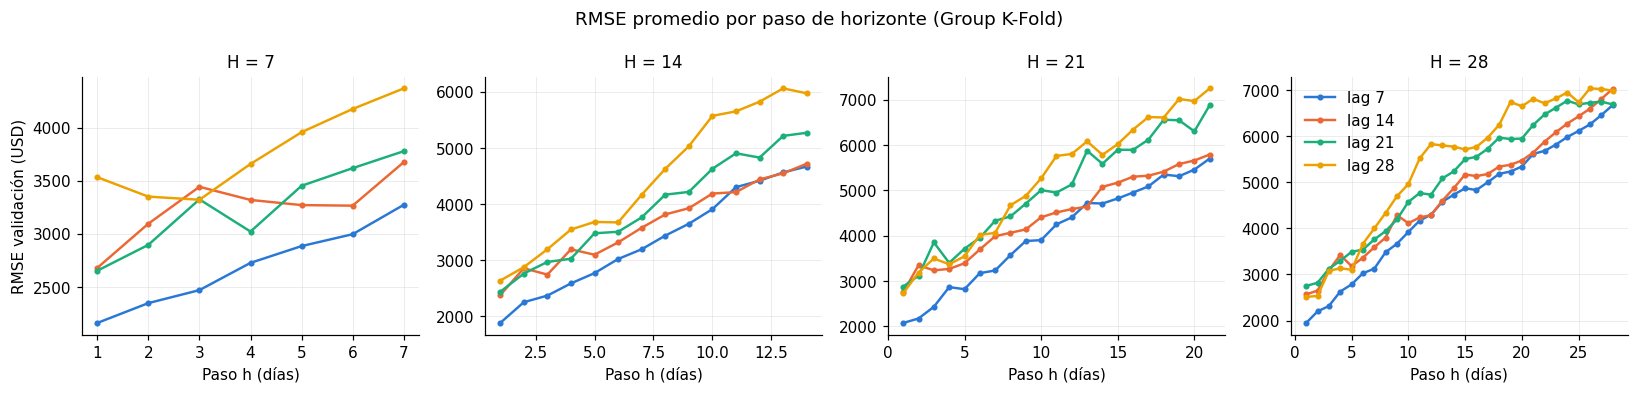

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for j, H in enumerate(HS):
    for L in LAGS:
        if (L, H, "gk") in DET:
            rh = np.mean([f["keras_val"]["rmse_h"] for f in DET[(L, H, "gk")]["folds"]], axis=0)
            axs[j].plot(range(1, H + 1), rh, marker="o", ms=3, color=COL_LAG[L], label=f"lag {L}")
    axs[j].set_title(f"H = {H}"); axs[j].set_xlabel("Paso h (días)")
axs[0].set_ylabel("RMSE validación (USD)"); axs[-1].legend()
fig.suptitle("RMSE promedio por paso de horizonte (Group K-Fold)"); fig.tight_layout()
guardar(fig, "eval_rmse_por_paso"); plt.show()

El RMSE crece con el paso del horizonte en las cuatro longitudes de H, de forma aproximadamente lineal. Con H = 28 y lag 7, por ejemplo, pasa de unos 1950 USD en h = 1 a unos 6700 USD en h = 28 (lectura de la figura). En casi todos los pasos el lag 7 tiene el menor error y el lag 28 el mayor. El crecimiento con h es el esperado para una serie cercana a una caminata aleatoria, cuya incertidumbre se acumula con el horizonte.

## 3.3 Tabla consolidada lag × horizonte

In [6]:
CONS = LARGA.groupby(["estrategia", "lag", "H"])[["RMSE", "MAPE", "MAE", "MSE", "BDS_pvalue_h1"]].mean().reset_index()
CONS.to_csv(RESULTS / "tabla_consolidada_lag_h.csv", index=False)
for met in ("RMSE", "MAPE"):
    print(f"\n{met} promedio de validación — Group K-Fold")
    display(CONS[CONS.estrategia == "Group K-Fold"].pivot(index="lag", columns="H", values=met).round(2))


RMSE promedio de validación — Group K-Fold


H,7,14,21,28
lag,,,,
7,2728.67,3482.70,4202.19,4706.15
14,3284.70,3724.43,4552.78,4978.11
21,3286.47,4055.85,5157.07,5279.43
28,3804.46,4636.53,5422.43,5616.73



MAPE promedio de validación — Group K-Fold


H,7,14,21,28
lag,,,,
7,7.71,8.29,9.86,14.34
14,7.65,9.83,11.70,13.07
21,8.67,9.93,11.83,12.72
28,10.10,13.39,12.27,13.20


Con Group K-Fold el RMSE medio de validación va de 2729 USD (lag 7, H 7) a 5617 USD (lag 28, H 28), y el MAPE de 7.7 % a 14.3 %. Para cada horizonte, el lag 7 es el mejor en RMSE (2729, 3483, 4202 y 4706 USD para H = 7, 14, 21 y 28), y el error crece tanto con H como con el lag. El MAPE sigue la misma tendencia, con algunas excepciones menores (por ejemplo, con H = 7 el lag 14 tiene un MAPE apenas inferior al del lag 7: 7.65 % frente a 7.71 %).

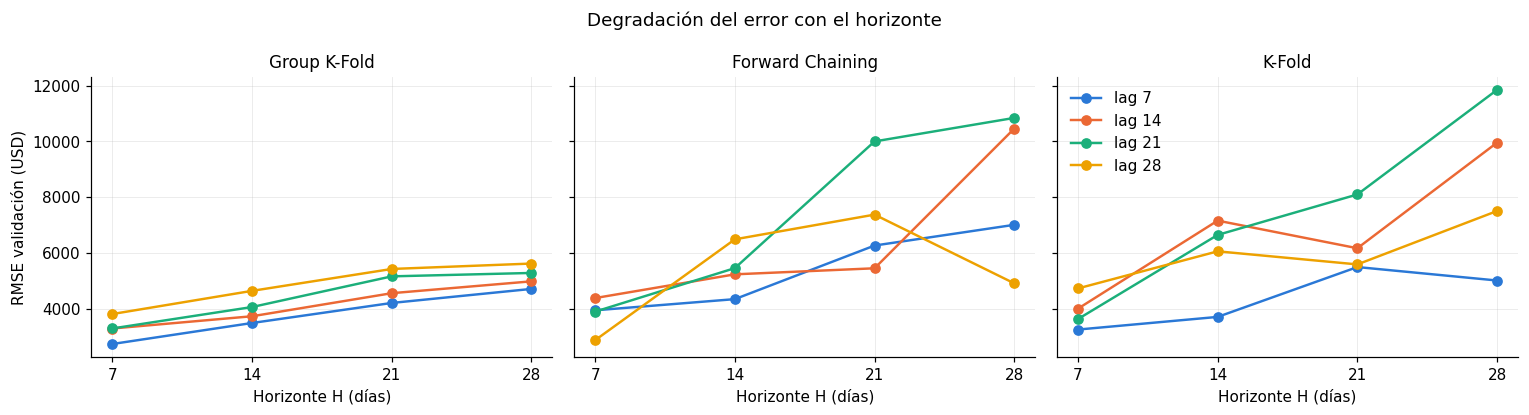

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, s in zip(axs, ESTRATEGIAS):
    g = CONS[CONS.estrategia == NOMBRE[s]]
    for L in LAGS:
        gl = g[g.lag == L].sort_values("H")
        ax.plot(gl.H, gl.RMSE, marker="o", ms=6, color=COL_LAG[L], label=f"lag {L}")
    ax.set_title(NOMBRE[s]); ax.set_xticks(HS); ax.set_xlabel("Horizonte H (días)")
axs[0].set_ylabel("RMSE validación (USD)"); axs[-1].legend()
fig.suptitle("Degradación del error con el horizonte"); fig.tight_layout()
guardar(fig, "eval_rmse_vs_H"); plt.show()

## 3.4 Comparación de estrategias de validación

In [8]:
COMP = CONS.rename(columns={"estrategia": "estrategia"})[["estrategia", "lag", "H", "RMSE", "MAPE", "MAE", "MSE", "BDS_pvalue_h1"]]
COMP.to_csv(RESULTS / "comparacion_estrategias.csv", index=False)
COMP.pivot_table(index=["lag", "H"], columns="estrategia", values="RMSE").round(1)

estrategia  Forward Chaining  Group K-Fold   K-Fold
lag H                                              
7   7                 3937.8        2728.7   3246.7
    14                4339.0        3482.7   3701.1
    21                6263.4        4202.2   5491.1
    28                7007.2        4706.2   5008.0
14  7                 4378.0        3284.7   3997.8
    14                5230.0        3724.4   7158.5
    21                5446.7        4552.8   6166.4
    28               10462.3        4978.1   9956.8
21  7                 3890.6        3286.5   3624.9
    14                5453.0        4055.9   6644.8
    21               10001.8        5157.1   8098.1
    28               10846.3        5279.4  11852.8
28  7                 2866.4        3804.5   4723.8
    14                6487.0        4636.5   6056.0
    21                7374.0        5422.4   5585.9
    28                4906.2        5616.7   7503.5

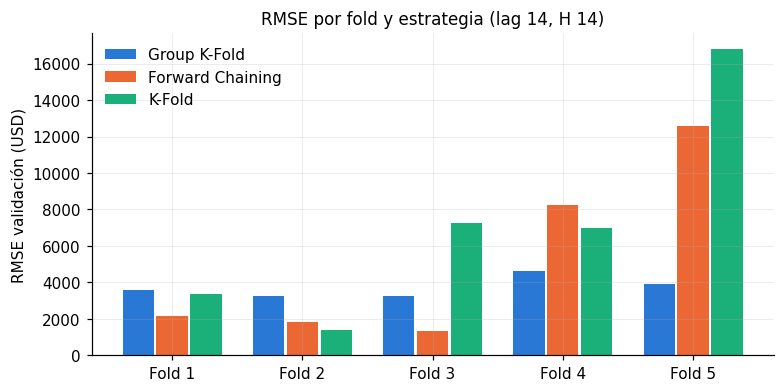

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.26
for k, s in enumerate(ESTRATEGIAS):
    if (14, 14, s) in DET:
        v = [f["keras_val"]["rmse"] for f in DET[(14, 14, s)]["folds"]]
        ax.bar(np.arange(len(v)) + (k - 1) * w, v, width=w - 0.02, color=COL_EST[s], label=NOMBRE[s])
ax.set_xticks(range(5)); ax.set_xticklabels([f"Fold {i}" for i in range(1, 6)])
ax.set_ylabel("RMSE validación (USD)"); ax.set_title("RMSE por fold y estrategia (lag 14, H 14)"); ax.legend()
guardar(fig, "eval_rmse_por_fold_estrategias"); plt.show()

Group K-Fold da el menor RMSE en 14 de las 16 configuraciones; las excepciones son lag 28 con H 7 y lag 28 con H 28, donde gana Forward Chaining. Esta ventaja no significa que Group K-Fold sea la estrategia más fiel. Al intercalar bloques de entrenamiento y validación a lo largo de toda la serie, el modelo entrena con datos posteriores a cada bloque de validación y con bloques vecinos de nivel de precio similar, lo que hace su estimación optimista. Forward Chaining es la única que respeta el orden temporal (entrena siempre con el pasado), pero con `timeseries-cv` valida sobre una ventana por fold y su estimación es muy variable. K-Fold combina los dos problemas: entrena con datos futuros y valida sobre una ventana.

En consecuencia, usamos Group K-Fold para comparar arquitecturas entre sí, donde su sesgo afecta a todas por igual, pero no como estimación del error futuro. Para eso reservamos el hold-out.

### Esquema de partición de cada estrategia

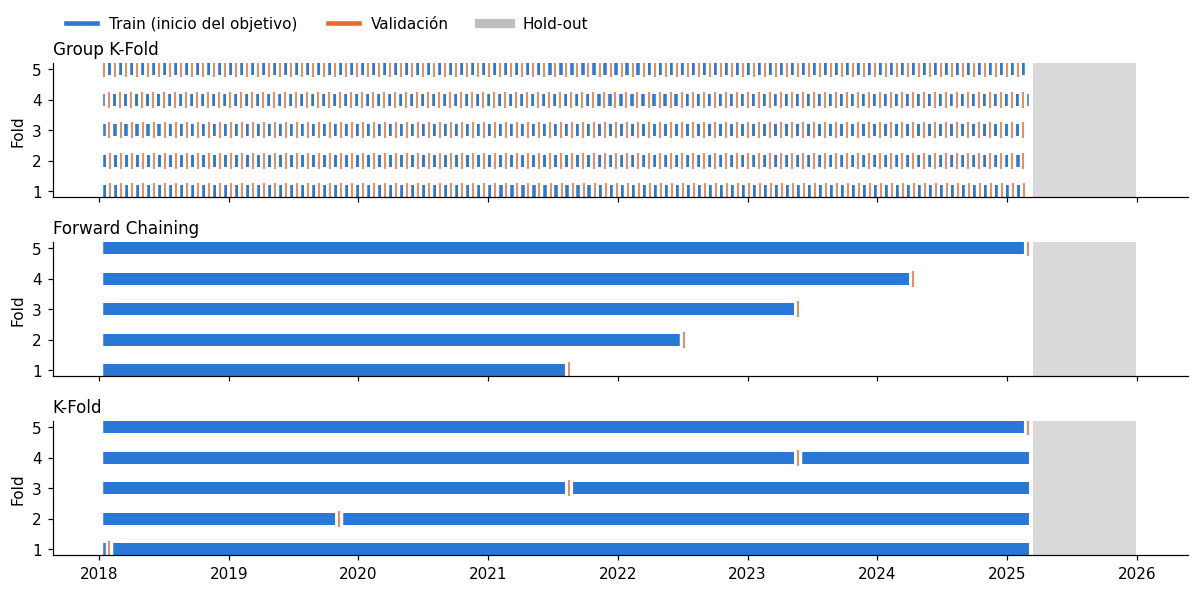

In [10]:
def esquema(L=14, H=14):
    fig, axs = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True)
    for ax, s in zip(axs, ESTRATEGIAS):
        z = np.load(RESULTS / "preds" / f"detail_L{L}_H{H}_{s}.npz")
        nf = len([k for k in z.files if k.endswith("_va_start")])
        for j in range(nf):
            for parte, c, lw in (("tr", COL[0], 5), ("va", COL[1], 9)):
                st = z[f"f{j}_{parte}_start"]; st = st[st >= 0] + L
                ax.scatter(DATES[st], np.full(len(st), j + 1), marker="|", s=lw * 12, color=c, lw=1)
        ax.axvspan(DATES[N_CV], DATES[-1], color="0.85", lw=0)
        ax.set_yticks(range(1, nf + 1)); ax.set_ylabel("Fold"); ax.set_title(NOMBRE[s], loc="left")
        ax.grid(False)
    from matplotlib.lines import Line2D
    axs[0].legend([Line2D([], [], color=COL[0], lw=3), Line2D([], [], color=COL[1], lw=3),
                   Line2D([], [], color="0.75", lw=6)], ["Train (inicio del objetivo)", "Validación", "Hold-out"],
                  ncol=3, loc="upper left", bbox_to_anchor=(0, 1.45))
    fig.tight_layout(); guardar(fig, f"esquema_particiones_L{L}_H{H}"); plt.show()

esquema()

El esquema muestra las tres particiones en la configuración (14, 14). En Group K-Fold los bloques de validación (naranja) se reparten a lo largo de 2018–2025 entre bloques de entrenamiento. En Forward Chaining el entrenamiento crece hacia adelante y la validación es una sola ventana inmediatamente posterior. En K-Fold la ventana de validación tiene entrenamiento antes y después. En ningún caso el hold-out (gris) participa.

## 3.5 Referencias: MLPRegressor y pronóstico ingenuo

In [11]:
BASEL = LARGA.groupby(["estrategia", "lag", "H"])[["RMSE", "RMSE_mlpregressor", "RMSE_ingenuo"]].mean().reset_index()
BASEL["MLP_mejor_que_ingenuo"] = BASEL.RMSE < BASEL.RMSE_ingenuo
BASEL.to_csv(RESULTS / "baselines_val.csv", index=False)
print("Configuraciones donde el MLP Keras supera al ingenuo:",
      BASEL.groupby("estrategia").MLP_mejor_que_ingenuo.agg(["sum", "size"]).to_string())
BASEL[BASEL.estrategia == "Group K-Fold"].round(1)

Configuraciones donde el MLP Keras supera al ingenuo:                   sum  size
estrategia                 
Forward Chaining    0    16
Group K-Fold        0    16
K-Fold              0    16


,estrategia,lag,H,RMSE,RMSE_mlpregressor,RMSE_ingenuo,MLP_mejor_que_ingenuo
16,Group K-Fold,7,7,2728.7,2879.7,2091.4,False
17,Group K-Fold,7,14,3482.7,3638.1,3090.8,False
18,Group K-Fold,7,21,4202.2,4333.4,3869.0,False
19,Group K-Fold,7,28,4706.2,4837.0,4478.6,False
20,Group K-Fold,14,7,3284.7,3666.2,2258.6,False
21,Group K-Fold,14,14,3724.4,4302.4,3074.4,False
22,Group K-Fold,14,21,4552.8,4731.6,3743.4,False
23,Group K-Fold,14,28,4978.1,5323.7,4365.6,False
24,Group K-Fold,21,7,3286.5,3648.6,2464.2,False
25,Group K-Fold,21,14,4055.9,4569.1,3352.1,False


**El MLP no supera al pronóstico ingenuo en ninguna de las 48 combinaciones** de configuración y estrategia. Con Group K-Fold su RMSE es entre 1.05 veces (lag 7, H 28) y 1.79 veces (lag 28, H 7) el del ingenuo. La brecha es menor con lag 7 y horizontes largos, y mayor con lag 28 y horizontes cortos, que es donde el ingenuo es más difícil de superar.

Frente a `MLPRegressor`, el MLP de Keras con arquitectura buscada es mejor en las 16 configuraciones con Group K-Fold, con ventajas de 2 % a 18 % en catorce de ellas y de 53 % y 123 % en lag 28 con H 14 y H 7. La búsqueda de arquitectura sí aporta frente a una red por defecto, pero ninguna de las dos redes captura algo que el último precio no contenga ya.

Este resultado es el que anticipamos en el EDA: la serie se comporta como una caminata aleatoria y la mejor predicción lineal del nivel es el último valor observado. Que la red quede por encima del ingenuo indica que no aprende a reproducir con exactitud esa persistencia: tiene que aproximar la identidad sobre la última entrada a través de capas ReLU y de una estandarización global, y cualquier imprecisión se convierte en error.

## 3.6 Modelo final en el hold-out

In [12]:
def ingenuo_holdout(L, H):
    idx = range(N_CV, len(y) - H + 1)
    P = np.array([[y[i - 1]] * H for i in idx]); Y = np.array([y[i:i + H] for i in idx])
    e = P - Y
    return float(np.sqrt((e ** 2).mean())), float(np.mean(np.abs(e / Y)) * 100)

filas = []
for (L, H), r in sorted(FIN.items()):
    rmse_i, mape_i = ingenuo_holdout(L, H)
    filas.append(dict(lag=L, H=H, arquitectura=str(tuple(r["arch"])), dropout_mask=str(tuple(r["mask"])),
                      RMSE=r["holdout_rmse"], MAPE=r["holdout_mape"], MAE=r["holdout_mae"], MSE=r["holdout_mse"],
                      RMSE_ingenuo=rmse_i, MAPE_ingenuo=mape_i, ventanas=r["n_holdout_windows"]))
HOLD = pd.DataFrame(filas)
HOLD.to_csv(RESULTS / "holdout_modelo_final.csv", index=False)
HOLD.round(2)

,lag,H,arquitectura,dropout_mask,RMSE,MAPE,MAE,MSE,RMSE_ingenuo,MAPE_ingenuo,ventanas
0,7,7,"(64,)","(False,)",5982.13,4.55,4634.76,3.578582e+07,3905.47,2.81,286
1,7,14,"(64,)","(False,)",9614.42,7.65,7780.36,9.243704e+07,5319.27,3.86,279
2,7,21,"(32,)","(False,)",9889.44,8.06,8213.25,9.780094e+07,6351.48,4.62,272
3,7,28,"(256,)","(False,)",18952.75,16.16,16604.76,3.592067e+08,7354.18,5.31,265
4,14,7,"(32, 64, 128)","(False, False, False)",5206.84,3.96,4032.41,2.711121e+07,3905.47,2.81,286
5,14,14,"(32, 256)","(False, False)",10710.71,8.94,8938.56,1.147193e+08,5319.27,3.86,279
6,14,21,"(32, 32, 128)","(False, False, False)",27554.88,23.93,25560.23,7.592712e+08,6351.48,4.62,272
7,14,28,"(64, 128)","(False, False)",24596.63,22.26,22970.39,6.049940e+08,7354.18,5.31,265
8,21,7,"(64, 128, 128)","(False, False, False)",8160.54,6.49,6939.30,6.659445e+07,3905.47,2.81,286
9,21,14,"(32, 256)","(False, False)",6929.21,5.44,5456.76,4.801399e+07,5319.27,3.86,279


En el hold-out el MLP también queda por encima del ingenuo en las 16 configuraciones, con razones de RMSE de 1.20 (lag 28, H 14) a 4.34 (lag 14, H 21). Los mejores resultados son lag 14 con H 7 (RMSE 5207 USD, MAPE 3.96 %) y lag 28 con H 7 (5261 USD, 3.99 %), frente a 3905 USD y 2.81 % del ingenuo. Cuatro configuraciones (lag 14 y lag 21 con H 21 y H 28) superan el 19 % de MAPE.

El error del hold-out es mucho mayor que el de validación con Group K-Fold. En lag 14 con H 14, por ejemplo, pasa de 3724 a 10 711 USD. Dos hechos lo explican. Primero, el optimismo de Group K-Fold descrito en 3.4. Segundo, el hold-out contiene el máximo histórico y precios por encima de todo el tramo de entrenamiento, de modo que la red extrapola (sección 1.2). El MAPE del ingenuo en el hold-out (2.8 % a 5.3 %) es menor que el MAPE de validación del MLP con Group K-Fold (7.7 % a 14.3 %), porque 2025 es el periodo de menor volatilidad de la muestra (sección 1.4).

La selección del lag por horizonte para la API se hace con el RMSE de validación de Group K-Fold y elige lag 7 en los cuatro horizontes. En el hold-out lag 7 no es el mejor en ningún horizonte: con H 28 su MAPE es 16.2 %, frente a 10.7 % de lag 28. Lo reportamos tal cual; usar el hold-out para corregir la elección invalidaría la evaluación.

## 3.7 Series reales y predichas (train, validación y hold-out)

Para cada (lag, H) graficamos la predicción a un paso (h = 1) del mejor, el mediano y el peor fold de Group K-Fold según RMSE de validación, junto con el modelo final en el hold-out.

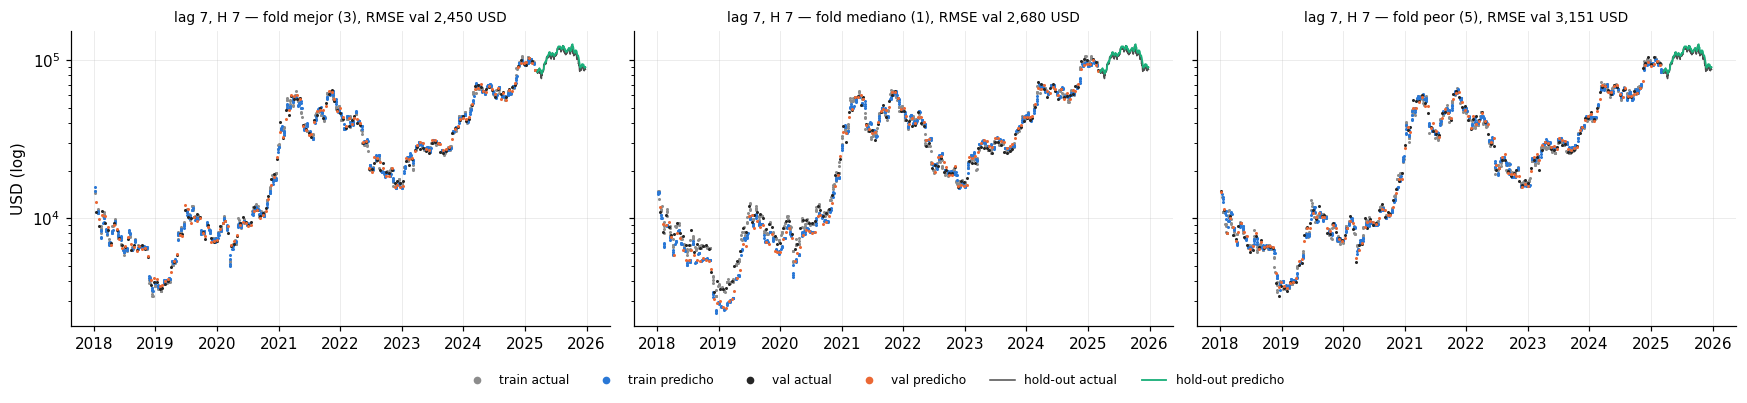

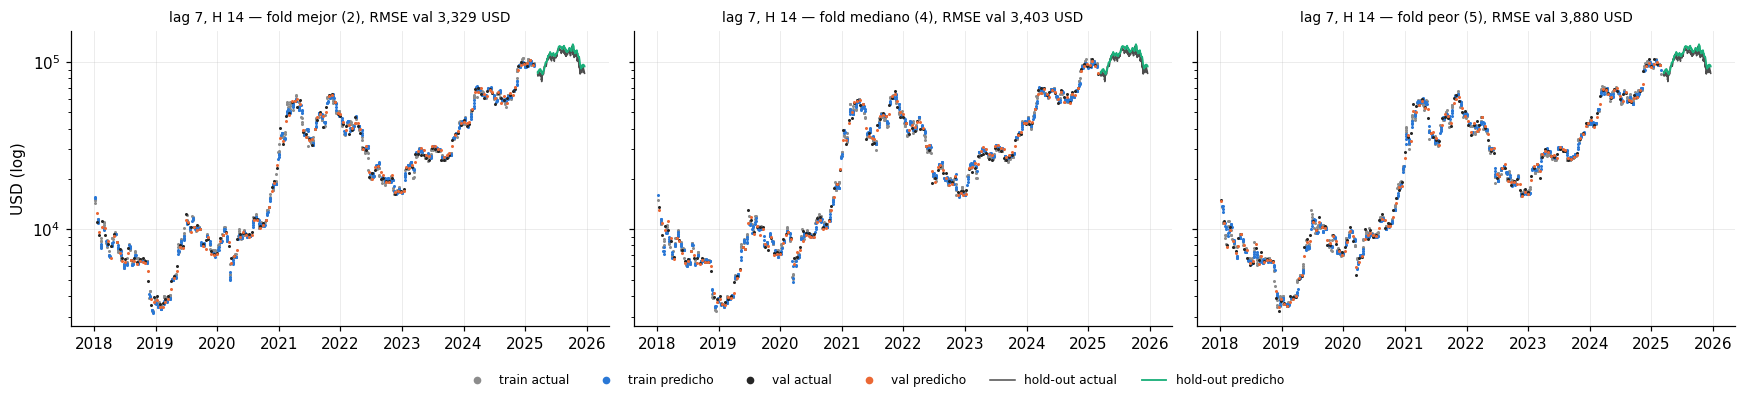

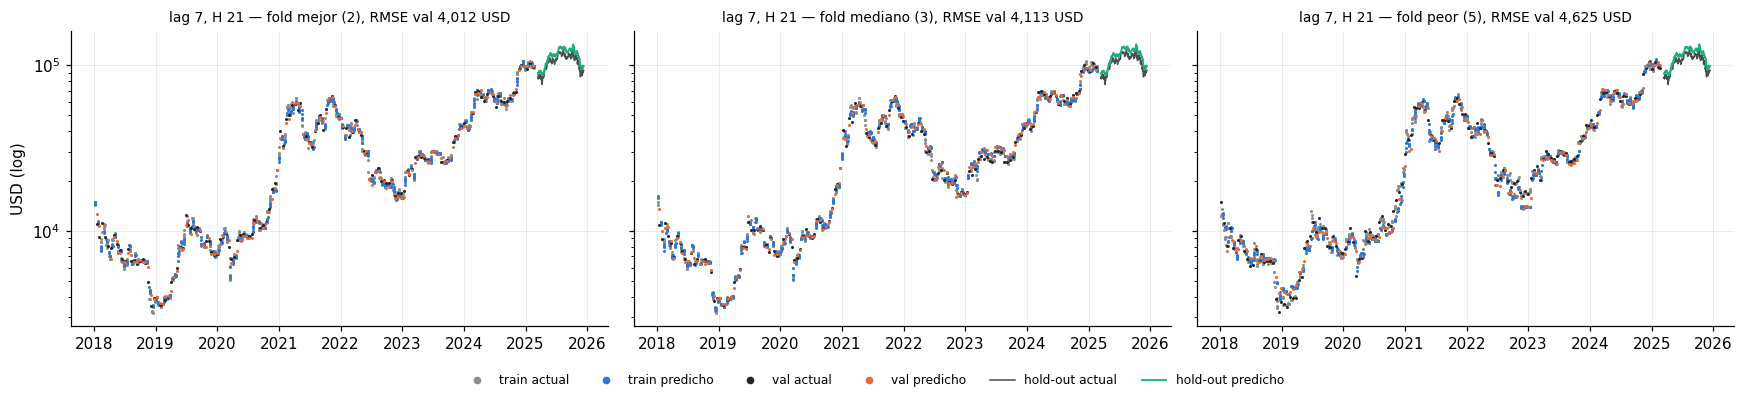

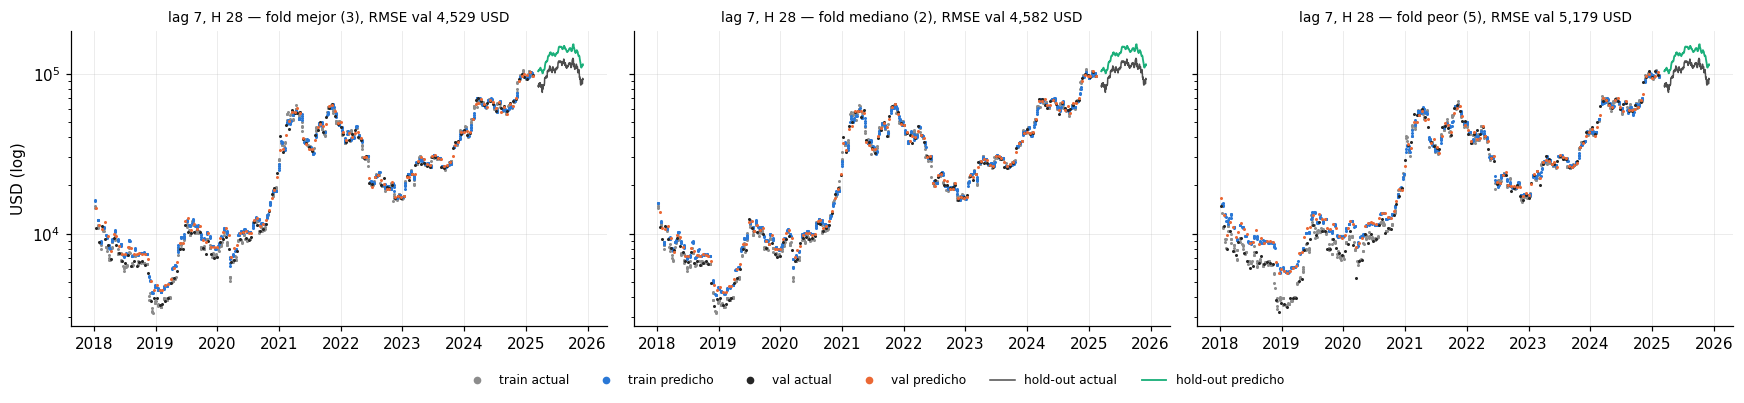

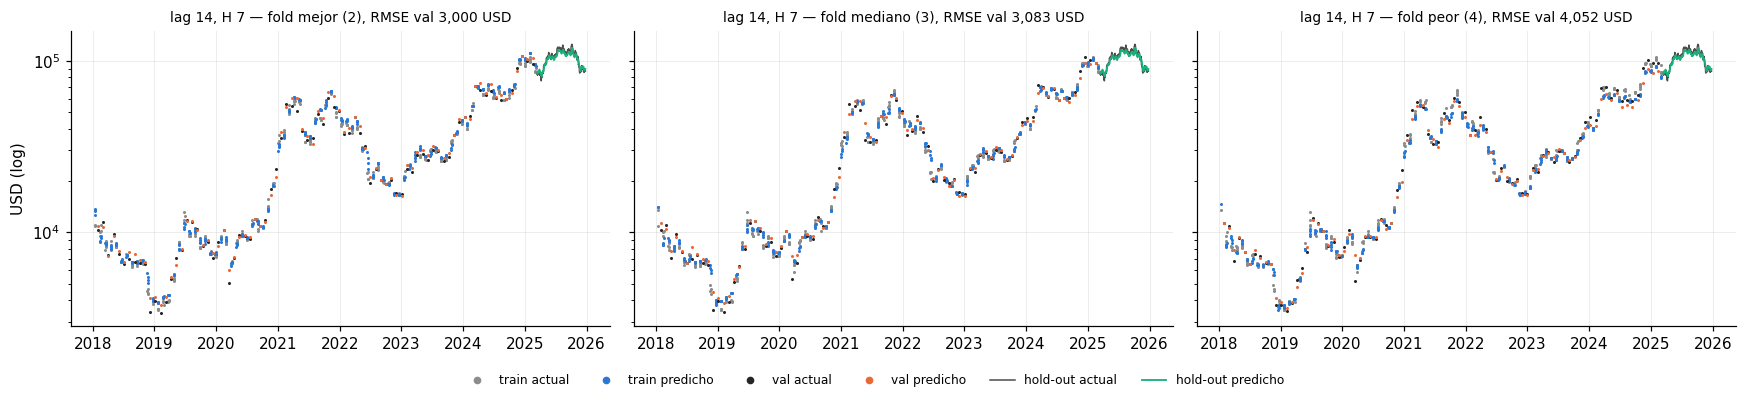

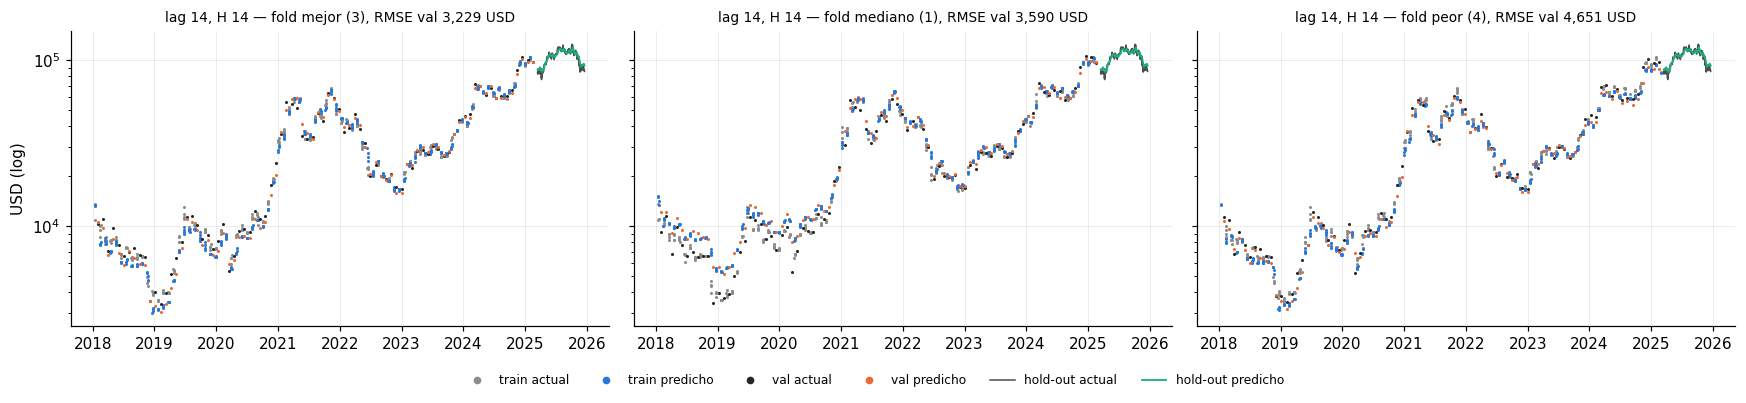

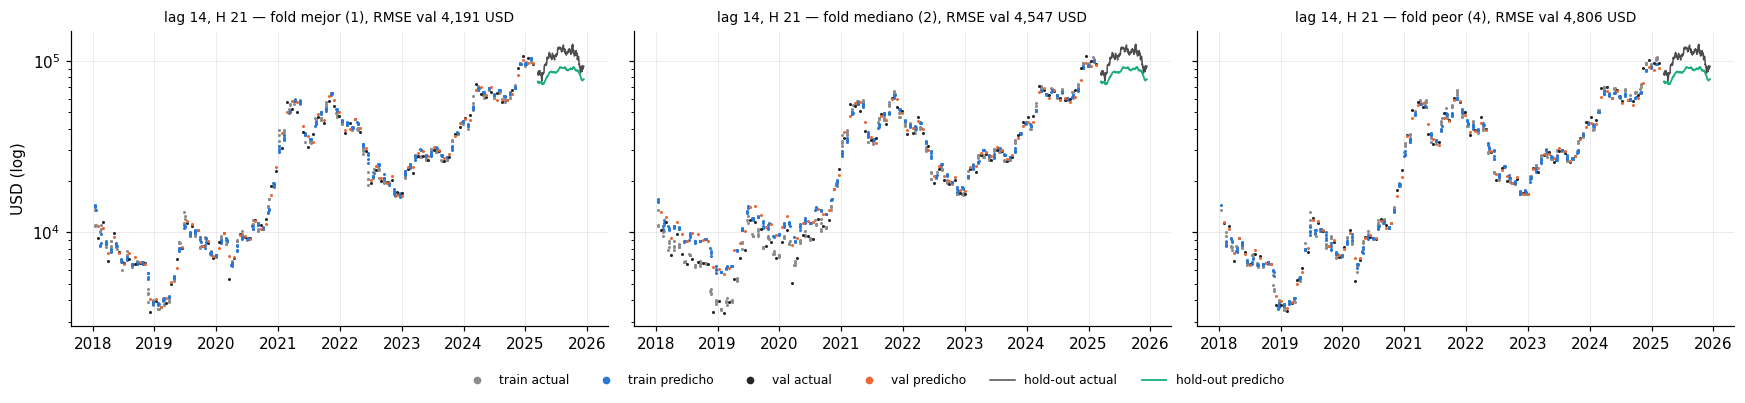

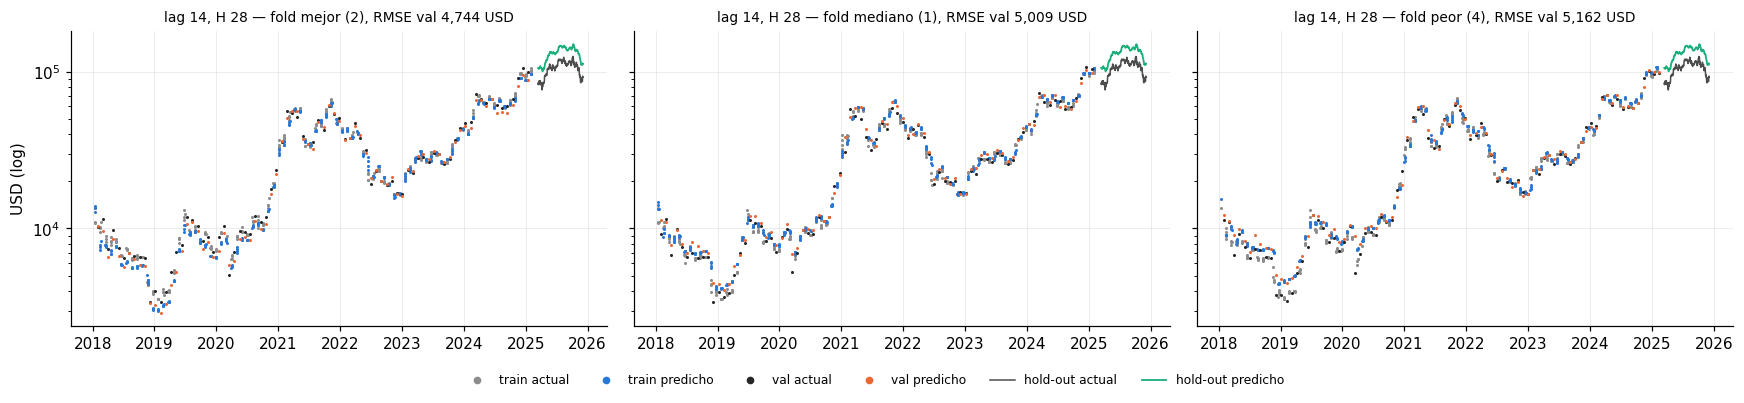

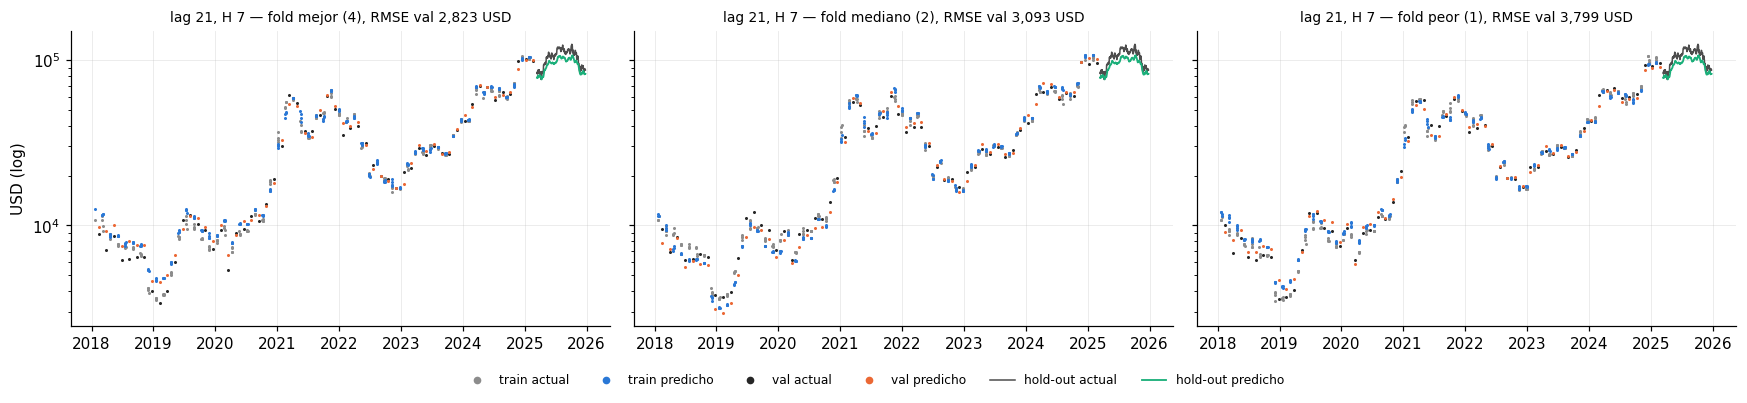

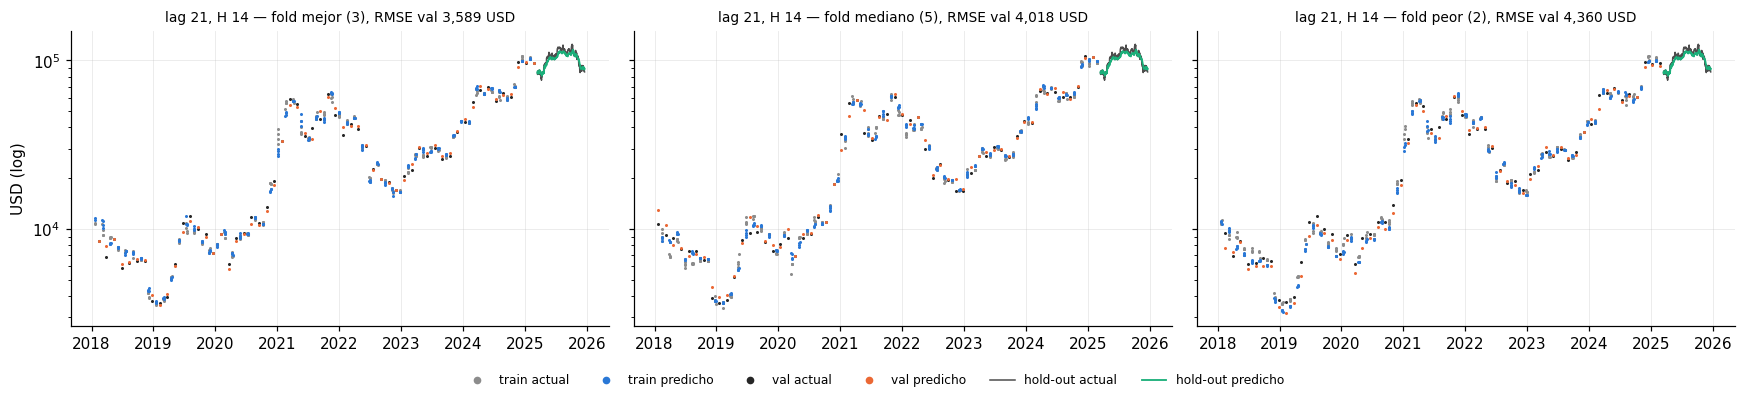

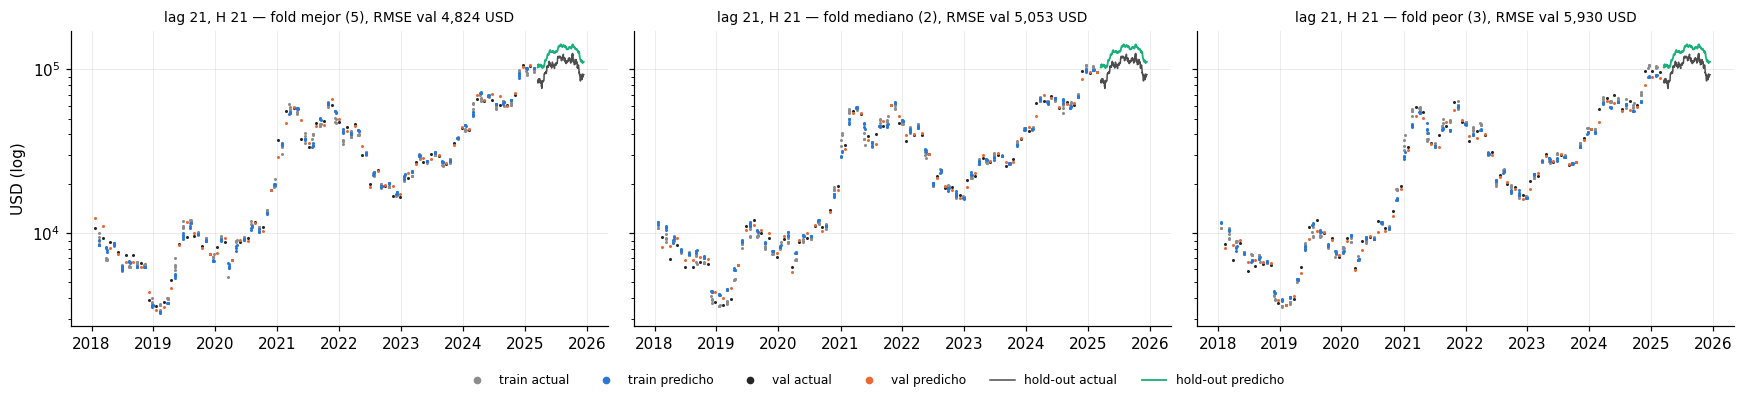

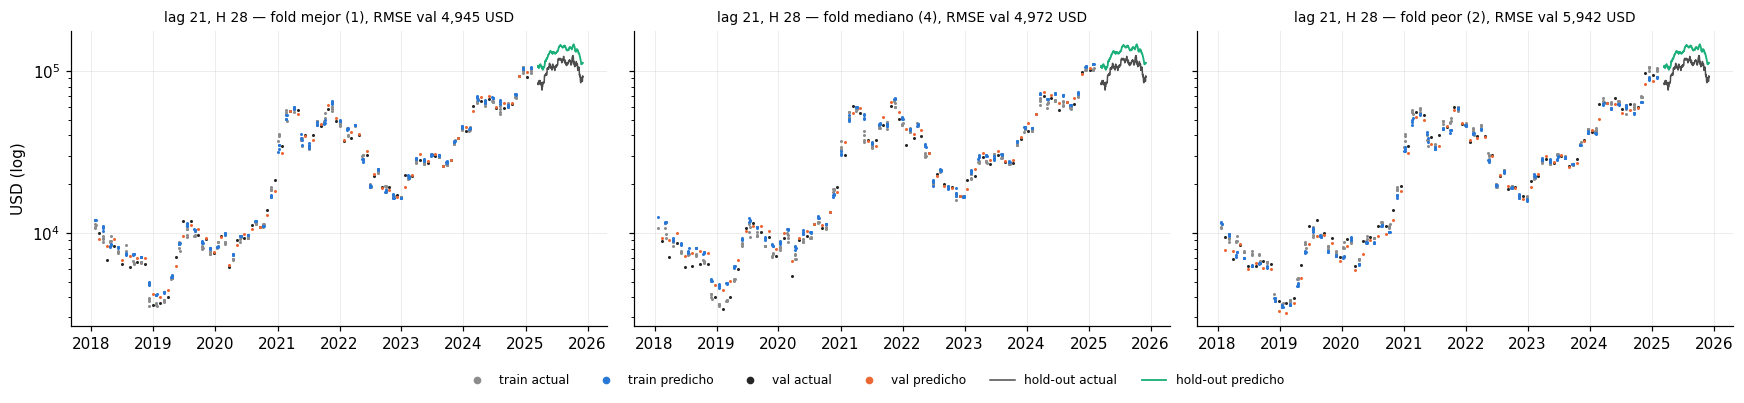

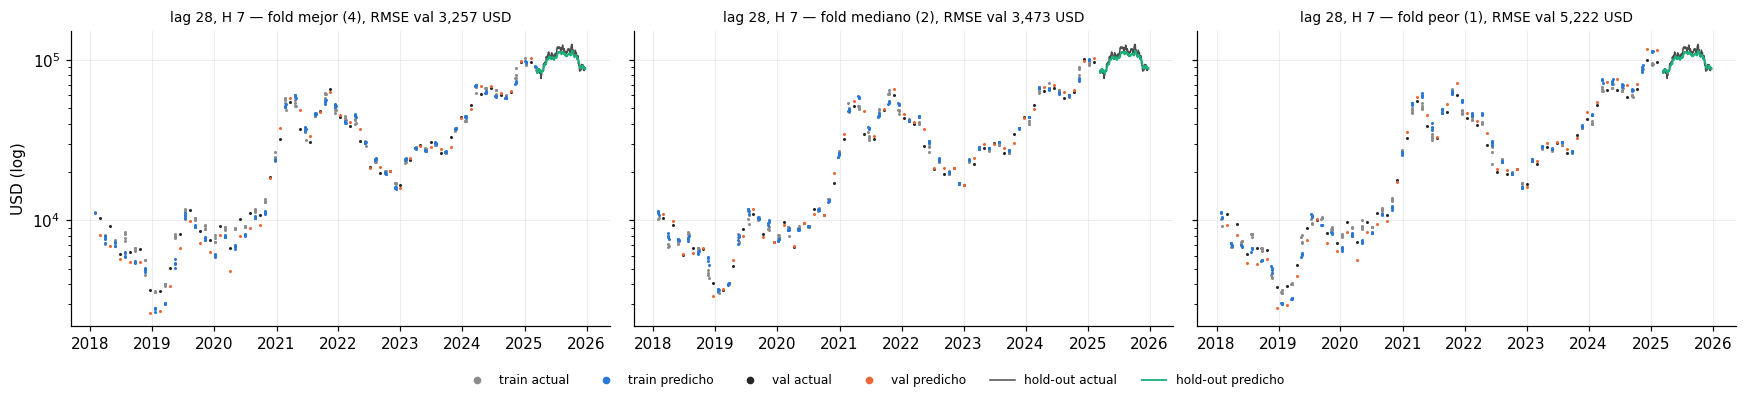

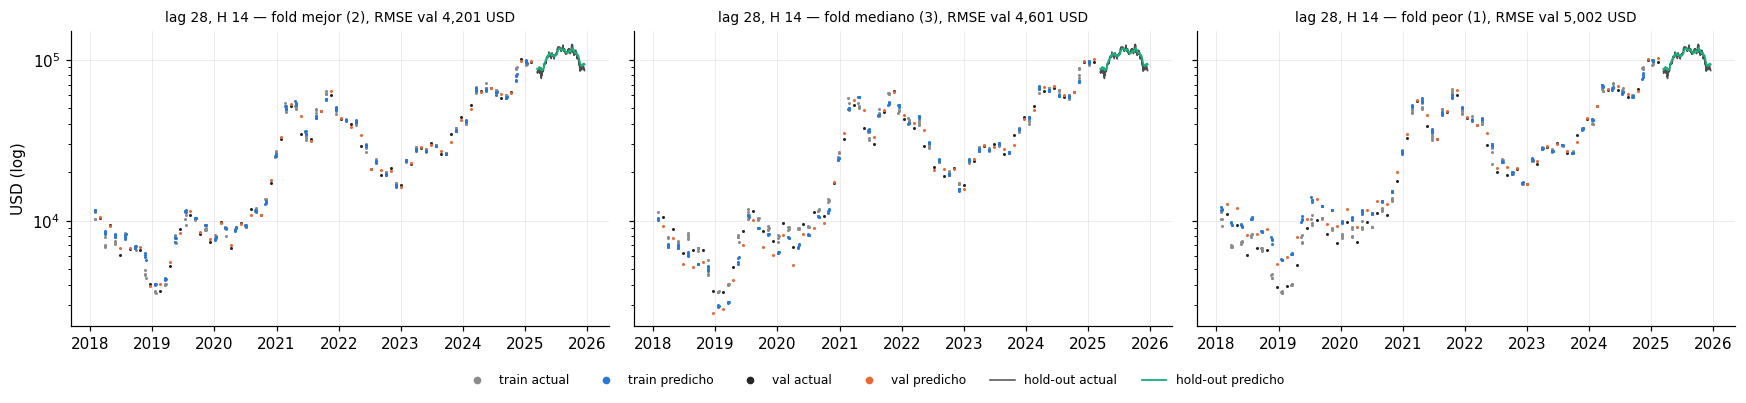

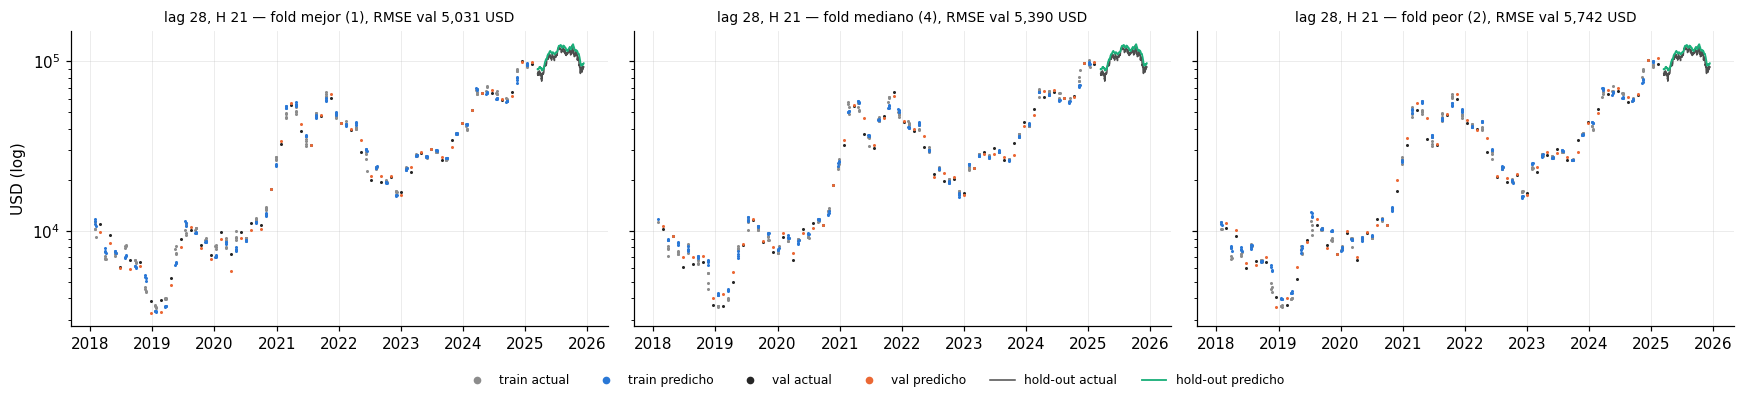

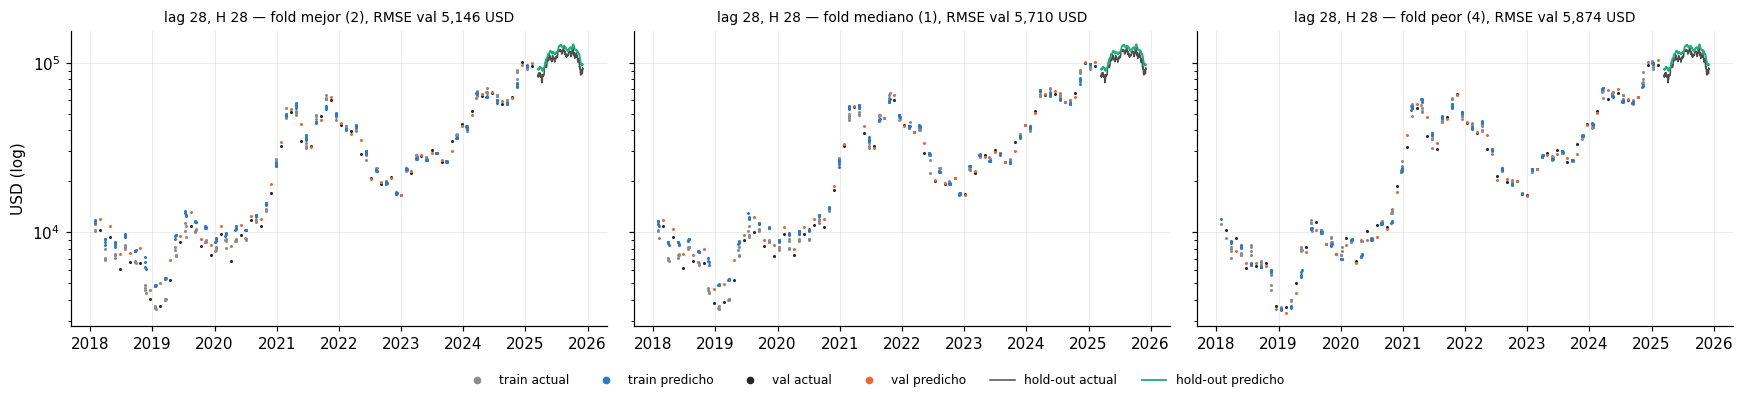

In [13]:
def serie_config(L, H, s="gk", mostrar=True):
    d = DET[(L, H, s)]; z = np.load(RESULTS / "preds" / f"detail_L{L}_H{H}_{s}.npz")
    rm = np.array([f["keras_val"]["rmse"] for f in d["folds"]]); orden = np.argsort(rm)
    elegidos = {"mejor": orden[0], "mediano": orden[len(orden) // 2], "peor": orden[-1]}
    fh = RESULTS / "models" / f"own_L{L}_H{H}_preds.npz"
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
    for ax, (et, j) in zip(axs, elegidos.items()):
        for parte, cr, cp, nom in (("tr", "0.55", COL[0], "train"), ("va", "0.15", COL[1], "val")):
            st = z[f"f{j}_{parte}_start"]; ok = st >= 0; t = DATES[st[ok] + L]
            o = np.argsort(t)
            ax.plot(t[o], z[f"f{j}_{parte}_real"][ok][o, 0], ".", ms=2, color=cr, label=f"{nom} actual")
            ax.plot(t[o], z[f"f{j}_{parte}_pred"][ok][o, 0], ".", ms=2, color=cp, label=f"{nom} predicho")
        if fh.exists():
            hz = np.load(fh); th = DATES[N_CV:N_CV + len(hz["real"])]
            ax.plot(th, hz["real"][:, 0], color="0.3", lw=1, label="hold-out actual")
            ax.plot(th, hz["pred"][:, 0], color=COL[2], lw=1.2, label="hold-out predicho")
        ax.set_yscale("log"); ax.set_title(f"lag {L}, H {H} — fold {et} ({j+1}), RMSE val {rm[j]:,.0f} USD", fontsize=9)
    axs[0].set_ylabel("USD (log)")
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, ncol=6, fontsize=8, markerscale=4, loc="lower center", bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout(); guardar(fig, f"serie_L{L}_H{H}_{s}")
    plt.show() if mostrar else plt.close(fig)

for L in LAGS:
    for H in HS:
        if (L, H, "gk") in DET:
            serie_config(L, H)

En los tramos de entrenamiento y validación las predicciones a un paso siguen de cerca al precio real en escala logarítmica, en todos los folds, también en el peor. En el hold-out el modelo final reproduce la forma de la serie con un desplazamiento: en lag 28 con H 28, por ejemplo, la predicción queda por encima del precio real durante casi todo el tramo. Ese sesgo sistemático, y no la forma de la curva, es lo que explica la mayor parte del error en el hold-out; el notebook 4 lo cuantifica.

## 3.8 Síntesis

- El MLP no supera al pronóstico ingenuo en ninguna configuración, ni en validación (48 de 48) ni en el hold-out (16 de 16). Sí supera a `MLPRegressor` en las 16 configuraciones con Group K-Fold.
- El error crece con el horizonte y con el lag; lag 7 es el mejor en validación, pero no en el hold-out.
- Group K-Fold produce la estimación más baja y estable, y también la más optimista. Forward Chaining y K-Fold, tal como los implementa `timeseries-cv`, validan una ventana por fold y su estimación es muy variable.
- En el hold-out el error está dominado por un desplazamiento sistemático de la predicción, asociado a precios fuera del rango de entrenamiento.